
# Predicting Chemotherapy Resistance from DNA Methylation Data

**Course:** Introduction to Profile Areas – Data Science  
**University:** Freie Universität Berlin  
**Semester:** Winter Semester 2026/27  
**Assignment:** Assignment 3

## Introduction

The objective of this project is to predict chemotherapy resistance using DNA methylation data and machine learning techniques.

DNA methylation is an epigenetic modification that can influence gene expression without changing the underlying DNA sequence. Differences in DNA methylation patterns may be associated with how cancer cells respond to chemotherapy.

In this project, we investigate whether DNA methylation measurements can be used to distinguish between chemotherapy-sensitive and chemoresistant cancer cell lines.

### Target Variable

- `0`: Chemotherapy-sensitive
- `1`: Chemotherapy-resistant

### Project Workflow

1. Load and inspect the datasets.
2. Merge the datasets using `Cell ID`.
3. Analyze and handle missing values.
4. Explore the target distribution.
5. Preprocess and standardize the features.
6. Train two machine learning classifiers using five-fold cross-validation.
7. Evaluate and compare the models using ROC-AUC.
8. Perform a statistical comparison of model performance.
9. Investigate class-imbalance handling techniques (optional).


In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1:  Load and inspect the dataset

## 1.1 Data Loading

The first step is to load the two provided datasets into Python using the Pandas library.

The datasets contain two different types of information:

- **Methylation data (`methylation.csv`):** Contains DNA methylation measurements for different CpG sites. These measurements will be used as input features for our machine learning models.
- **Chemotherapy resistance labels (`chemoresistance_labels.csv`):** Contains the corresponding chemotherapy response labels for each cell line.

Both datasets share a common identifier, `Cell ID`, which will be used to combine them in the next step.

### Initial Data Inspection

After loading the datasets, we inspect their dimensions, column names, and first few observations. This helps us understand their structure and identify potential data-quality issues before proceeding with data preparation.

In [11]:
methylation_df = pd.read_csv("methylation.csv")
chemoresistance_lables_df = pd.read_csv("chemoresistance_labels.csv")

print("Methylation dataset shape: ", methylation_df.shape)
print("Labels dataset shape: ", chemoresistance_lables_df.shape)

print("\nMethylation dataset: ")
display(methylation_df.head())

print("\nChemotherapy resistance labels")
display(chemoresistance_lables_df.head())


Methylation dataset shape:  (1000, 51)
Labels dataset shape:  (1000, 2)

Methylation dataset: 


,Unnamed: 0,CpG_0,CpG_1,CpG_2,CpG_3,CpG_4,CpG_5,CpG_6,CpG_7,CpG_8,...,CpG_40,CpG_41,CpG_42,CpG_43,CpG_44,CpG_45,CpG_46,CpG_47,CpG_48,CpG_49
0,Cell_0,0.773956,0.438878,0.858598,0.697368,0.094177,0.975622,0.761140,0.786064,0.128114,...,0.437152,0.832678,0.700265,0.312367,0.832260,0.804764,0.387478,0.288328,0.682496,0.139752
1,Cell_1,0.199908,0.007362,0.786924,0.664851,0.705165,0.780729,0.458916,0.568741,0.139797,...,0.152312,0.696320,0.446156,0.381021,0.301512,0.630283,0.361813,0.087650,0.118006,0.961898
2,Cell_2,0.908581,0.699707,0.265870,0.969176,0.778751,0.716890,0.449362,0.272242,0.096391,...,0.486658,0.490707,0.937826,0.571728,0.473489,0.266976,0.331569,0.520672,0.438911,0.021612
3,Cell_3,0.826292,0.896161,0.140249,0.554036,0.108576,0.672240,0.281234,0.659423,0.726995,...,0.936813,0.240971,0.122758,0.831113,0.153284,0.179268,0.599383,0.874562,0.196435,0.310324
4,Cell_4,0.777405,0.971826,0.500741,0.143898,0.013936,0.229656,0.131822,0.677659,0.121833,...,0.829429,0.796817,0.232641,0.530770,0.606016,0.867739,0.603107,0.412572,0.374184,0.425882



Chemotherapy resistance labels


,Unnamed: 0,Chemotherapy_Resistance
0,Cell_0,0
1,Cell_1,0
2,Cell_2,0
3,Cell_3,0
4,Cell_4,1


## 1.2. Dataset Structure and Initial Data Quality Assessment

Before combining the two datasets, we perform an initial inspection to understand their structure and assess their data quality.

The inspection focuses on the following aspects:

- **Column names:** Identify the available variables, including the common identifier (`Cell ID`) and the target variable.
- **Data types:** Determine whether the methylation measurements are stored as numerical values and whether the labels have an appropriate data type.
- **Missing values:** Identify incomplete observations in both datasets and determine which columns contain missing values.
- **Duplicate identifiers:** Check whether `Cell ID` occurs more than once in either dataset, as duplicate identifiers may affect the merging process.

These checks are important because data-quality issues can influence subsequent preprocessing, model training, and evaluation.

The results of this inspection will guide our decisions about merging the datasets and handling missing or duplicated observations.

In [12]:
print("############### METHYLATION DATASET ###############")

print("\nColumn names: ", methylation_df.columns.tolist())
print("\nData types: ", methylation_df.value_counts())
print("\nMissing values: ", methylation_df.isnull().sum().sum())
print("\nMissing values per column:", methylation_df.isnull().sum())
print("\nFirst 10 identifiers: ", methylation_df["Unnamed: 0"].head(10).tolist())


print("\n\n############### CHEMOTHERAPY RESISTANCE LABELS ###############")

print("\nColumn names: ", chemoresistance_lables_df.columns.tolist())
print("\nData types: ", chemoresistance_lables_df.value_counts())
print("\nMissing values: ", chemoresistance_lables_df.isnull().sum().sum())
print("\nMissing values per column:", chemoresistance_lables_df.isnull().sum())
print("\nFirst 10 identifiers: ", chemoresistance_lables_df["Unnamed: 0"].head(10).tolist())


print("\n\n############### CELL ID CHECKS ###############")

print("Duplicate identifiers in methylation dataset: ", methylation_df["Unnamed: 0"].duplicated().sum())

print("Duplicate identifiers in labels dataset: ", methylation_df["Unnamed: 0"].duplicated().sum())




############### METHYLATION DATASET ###############

Column names:  ['Unnamed: 0', 'CpG_0', 'CpG_1', 'CpG_2', 'CpG_3', 'CpG_4', 'CpG_5', 'CpG_6', 'CpG_7', 'CpG_8', 'CpG_9', 'CpG_10', 'CpG_11', 'CpG_12', 'CpG_13', 'CpG_14', 'CpG_15', 'CpG_16', 'CpG_17', 'CpG_18', 'CpG_19', 'CpG_20', 'CpG_21', 'CpG_22', 'CpG_23', 'CpG_24', 'CpG_25', 'CpG_26', 'CpG_27', 'CpG_28', 'CpG_29', 'CpG_30', 'CpG_31', 'CpG_32', 'CpG_33', 'CpG_34', 'CpG_35', 'CpG_36', 'CpG_37', 'CpG_38', 'CpG_39', 'CpG_40', 'CpG_41', 'CpG_42', 'CpG_43', 'CpG_44', 'CpG_45', 'CpG_46', 'CpG_47', 'CpG_48', 'CpG_49']

Data types:  Series([], Name: count, dtype: int64)

Missing values:  4203

Missing values per column: Unnamed: 0      0
CpG_0          30
CpG_1          26
CpG_2          28
CpG_3          23
CpG_4          30
CpG_5          31
CpG_6          30
CpG_7          20
CpG_8          26
CpG_9          25
CpG_10         15
CpG_11         24
CpG_12         23
CpG_13         35
CpG_14        990
CpG_15         25
CpG_16         25


## 1.3 Dataset Integration

The two datasets contain a common identifier stored in the column `Unnamed: 0`, rather than explicitly named `Cell ID`.

To make the datasets easier to work with, we rename this column to `Cell ID` in both DataFrames.

We then combine the methylation measurements and chemotherapy resistance labels using this common identifier. Before merging, we check that the identifiers are unique and correspond between the two datasets.

This ensures that each methylation profile is associated with the correct chemotherapy resistance label.

In [13]:
# Rename the identifier column in both datasets
methylation_df = methylation_df.rename(
    columns={"Unnamed: 0": "Cell ID"}
)

chemoresistance_lables_df = chemoresistance_lables_df.rename(
    columns={"Unnamed: 0": "Cell ID"}
)


# Verify that identifiers are unique
assert methylation_df["Cell ID"].is_unique, \
    "Duplicate identifiers found in methylation dataset."

assert chemoresistance_lables_df["Cell ID"].is_unique, \
    "Duplicate identifiers found in labels dataset."


# Merge the datasets using Cell ID
merged_df = pd.merge(
    methylation_df,
    chemoresistance_lables_df,
    on="Cell ID",
    how="inner",
    validate="one_to_one"
)


# Display the merged dataset
print("Merged dataset shape:", merged_df.shape)

display(merged_df.head())

Merged dataset shape: (1000, 52)


,Cell ID,CpG_0,CpG_1,CpG_2,CpG_3,CpG_4,CpG_5,CpG_6,CpG_7,CpG_8,...,CpG_41,CpG_42,CpG_43,CpG_44,CpG_45,CpG_46,CpG_47,CpG_48,CpG_49,Chemotherapy_Resistance
0,Cell_0,0.773956,0.438878,0.858598,0.697368,0.094177,0.975622,0.761140,0.786064,0.128114,...,0.832678,0.700265,0.312367,0.832260,0.804764,0.387478,0.288328,0.682496,0.139752,0
1,Cell_1,0.199908,0.007362,0.786924,0.664851,0.705165,0.780729,0.458916,0.568741,0.139797,...,0.696320,0.446156,0.381021,0.301512,0.630283,0.361813,0.087650,0.118006,0.961898,0
2,Cell_2,0.908581,0.699707,0.265870,0.969176,0.778751,0.716890,0.449362,0.272242,0.096391,...,0.490707,0.937826,0.571728,0.473489,0.266976,0.331569,0.520672,0.438911,0.021612,0
3,Cell_3,0.826292,0.896161,0.140249,0.554036,0.108576,0.672240,0.281234,0.659423,0.726995,...,0.240971,0.122758,0.831113,0.153284,0.179268,0.599383,0.874562,0.196435,0.310324,0
4,Cell_4,0.777405,0.971826,0.500741,0.143898,0.013936,0.229656,0.131822,0.677659,0.121833,...,0.796817,0.232641,0.530770,0.606016,0.867739,0.603107,0.412572,0.374184,0.425882,1


## 5. Missing Value Analysis

Missing values are an important data-quality issue because incomplete feature measurements can affect machine learning model training and prediction performance.

We examine missing values in the merged dataset to identify:

- The total number of missing values.
- The number and percentage of missing values in each feature.
- The number of observations containing at least one missing value.
- Whether the target variable contains missing values.

This analysis will help us decide how to handle incomplete observations and features during the preprocessing stage.

We do not perform imputation or remove features at this stage. These decisions will be made and justified before model training.

In [14]:
# Calculate missing values per column and percentage...
missing_counts = merged_df.isnull().sum()
missing_percentages = (merged_df.isnull().mean() * 100)

missing_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage (%)": missing_percentages
})

# Display only columns containing missing values...
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

print("Total missing values:", merged_df.isnull().sum().sum())
print("Rows containing at least one missing value:", merged_df.isnull().any(axis=1).sum())
print("Missing target values:", merged_df["Chemotherapy_Resistance"].isnull().sum())

print("\nMissing values by column:")
display(missing_summary)

Total missing values: 4203
Rows containing at least one missing value: 1000
Missing target values: 0

Missing values by column:


,Missing Values,Missing Percentage (%)
CpG_14,990,99.0
CpG_25,990,99.0
CpG_33,990,99.0
CpG_46,36,3.6
CpG_13,35,3.5
CpG_27,33,3.3
CpG_42,32,3.2
CpG_5,31,3.1
CpG_48,31,3.1
CpG_0,30,3.0


## 6. Target Variable Distribution

The target variable, `Chemotherapy_Resistance`, represents the chemotherapy response of each cell line.

It contains two possible classes:

- **0:** Chemotherapy-sensitive.
- **1:** Chemotherapy-resistant.

We examine the frequency of each class using a histogram. This allows us to understand the distribution of the target variable and identify potential class imbalance.

Class imbalance is relevant because a machine learning classifier may perform poorly on a minority class if the training process is dominated by the majority class.

Target class distribution:
Chemotherapy_Resistance
0    850
1    150
Name: count, dtype: int64


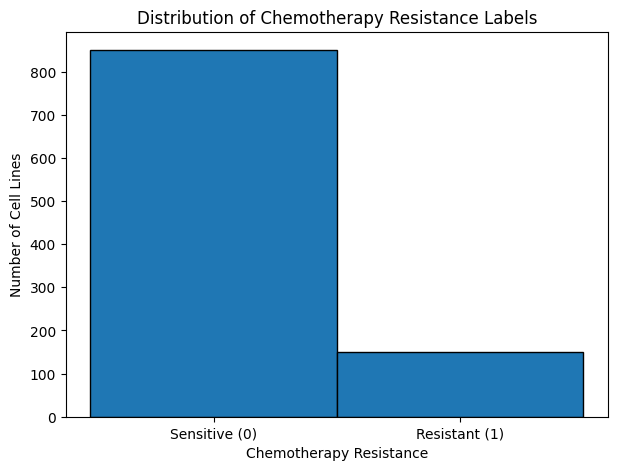

In [15]:
# Calculate the number of observations in each class
target_counts = merged_df["Chemotherapy_Resistance"].value_counts().sort_index()

print("Target class distribution:")
print(target_counts)

# Plot histogram
plt.figure(figsize=(7, 5))

plt.hist(
    merged_df["Chemotherapy_Resistance"],
    bins=[-0.5, 0.5, 1.5],
    edgecolor="black"
)

plt.xticks([0, 1], ["Sensitive (0)", "Resistant (1)"])
plt.xlabel("Chemotherapy Resistance")
plt.ylabel("Number of Cell Lines")
plt.title("Distribution of Chemotherapy Resistance Labels")

plt.show()

## 7. Data Preprocessing and Model Evaluation

In this step, we prepare the methylation data for machine learning and evaluate two classification models using five-fold cross-validation.

Before training, we need to address missing feature values and standardize the numerical measurements.

We use a preprocessing pipeline to ensure that data preparation is performed correctly within each cross-validation fold.

### Preventing Data Leakage

Data leakage occurs when information from the validation or test data influences the training process. This can lead to overly optimistic performance estimates.

To prevent data leakage:

- Missing values are imputed using statistics calculated only from the training portion of each fold.
- Standardization parameters are calculated only from the training portion of each fold.
- The learned transformations are then applied to the corresponding validation fold.

### Model Evaluation

We evaluate two classification algorithms using five-fold cross-validation. Each model is trained on four folds and evaluated on the remaining fold, repeating the process until every fold has been used for validation.

The models will be compared using the ROC-AUC metric.

In [27]:

# Separate input features and target variable
X = merged_df.drop(
    columns=["Cell ID", "Chemotherapy_Resistance"]
)

y = merged_df["Chemotherapy_Resistance"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)


Feature matrix shape: (1000, 50)
Target vector shape: (1000,)


In [28]:

# Import required libraries
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate


RANDOM_STATE = 42


# Define the two classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE
    )
}

# Define stratified five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Store evaluation results
cv_results = {}

# Train and evaluate both models
for model_name, classifier in models.items():

    # Build preprocessing and classification pipeline
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    # Perform five-fold cross-validation
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        return_train_score=False
    )

    # Save ROC-AUC scores
    cv_results[model_name] = scores["test_score"]

    # Display individual fold results
    print(f"\n{model_name}")
    for fold, score in enumerate(scores["test_score"], start=1):
        print(f"Fold {fold}: ROC-AUC = {score:.4f}")

    # Display average performance
    print(f"Mean ROC-AUC: {scores['test_score'].mean():.4f}")
    print(f"Standard Deviation: {scores['test_score'].std():.4f}")



Logistic Regression
Fold 1: ROC-AUC = 0.8929
Fold 2: ROC-AUC = 0.8327
Fold 3: ROC-AUC = 0.8831
Fold 4: ROC-AUC = 0.8957
Fold 5: ROC-AUC = 0.8616
Mean ROC-AUC: 0.8732
Standard Deviation: 0.0235

Random Forest
Fold 1: ROC-AUC = 0.7035
Fold 2: ROC-AUC = 0.6577
Fold 3: ROC-AUC = 0.7680
Fold 4: ROC-AUC = 0.7821
Fold 5: ROC-AUC = 0.7758
Mean ROC-AUC: 0.7374
Standard Deviation: 0.0488



### 8.1 Define Features, Target, and Cross-Validation Strategy

The methylation measurements are used as input features (X), while the `Chemotherapy_Resistance` variable is used as the target (y).

We apply stratified five-fold cross-validation to evaluate the classification models. Stratification preserves approximately the same proportion of chemotherapy-sensitive and chemoresistant cell lines in each fold.

Before splitting the data, observations are shuffled to reduce the influence of their original ordering. We also use a fixed random seed to ensure reproducibility.

In five-fold cross-validation, the dataset is divided into five subsets. Each subset is used once for validation, while the remaining four subsets are used for training.


In [20]:

from sklearn.model_selection import StratifiedKFold

# Define stratified five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Display dataset information
print("Number of observations:", X.shape[0])
print("Number of features:", X.shape[1])

print("\nTarget distribution:")
print(y.value_counts().sort_index())

# Inspect the class distribution in each fold
for fold, (train_index, validation_index) in enumerate(
    cv.split(X, y), start=1
):
    print(f"\nFold {fold}")
    print("Training observations:", len(train_index))
    print("Validation observations:", len(validation_index))
    print(
        "Validation class distribution:",
        y.iloc[validation_index].value_counts().sort_index().to_dict()
    )


Number of observations: 1000
Number of features: 50

Target distribution:
Chemotherapy_Resistance
0    850
1    150
Name: count, dtype: int64

Fold 1
Training observations: 800
Validation observations: 200
Validation class distribution: {0: 170, 1: 30}

Fold 2
Training observations: 800
Validation observations: 200
Validation class distribution: {0: 170, 1: 30}

Fold 3
Training observations: 800
Validation observations: 200
Validation class distribution: {0: 170, 1: 30}

Fold 4
Training observations: 800
Validation observations: 200
Validation class distribution: {0: 170, 1: 30}

Fold 5
Training observations: 800
Validation observations: 200
Validation class distribution: {0: 170, 1: 30}


#### Interpretation

The dataset contains 1,000 observations and 50 methylation features. The target variable consists of 850 chemotherapy-sensitive cell lines (85%) and 150 chemoresistant cell lines (15%).

This indicates a class imbalance, with chemotherapy-sensitive cell lines representing the majority class.

We applied stratified five-fold cross-validation to preserve the class distribution across the validation folds. Each fold contains 800 training observations and 200 validation observations, with 170 sensitive and 30 resistant cell lines in each validation set.

This ensures consistent class proportions during model evaluation. However, the class imbalance may still affect classification performance and will be investigated further using imbalance-handling techniques.

### 8.2 Cross-Validation Results

We evaluate the performance of Logistic Regression and Random Forest using the ROC-AUC scores obtained from five-fold cross-validation.

For each classifier, we examine:

- The ROC-AUC score for each individual fold.
- The mean ROC-AUC across all five folds.
- The standard deviation of the ROC-AUC scores.

The mean ROC-AUC provides an estimate of the model's overall discrimination performance, while the standard deviation indicates how much its performance varies across the different folds.

We also visualize the fold-wise ROC-AUC scores to compare the performance and consistency of the two classifiers.

A higher ROC-AUC indicates better discrimination between chemotherapy-sensitive and chemoresistant cell lines.

ROC-AUC scores for each fold:


,Logistic Regression,Random Forest
0,0.892941,0.703529
1,0.832745,0.657745
2,0.883137,0.768039
3,0.895686,0.782059
4,0.861569,0.775784



Summary of model performance:


,Mean ROC-AUC,Standard Deviation
Logistic Regression,0.873216,0.026296
Random Forest,0.737431,0.054540


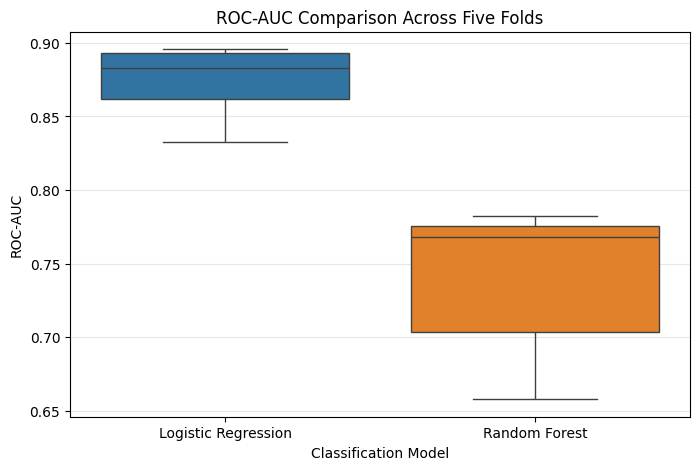

In [21]:
# Create a DataFrame containing the ROC-AUC scores
results_df = pd.DataFrame(cv_results)

# Display individual fold results
print("ROC-AUC scores for each fold:")
display(results_df)

# Calculate summary statistics
summary_df = pd.DataFrame({
    "Mean ROC-AUC": results_df.mean(),
    "Standard Deviation": results_df.std()
})

print("\nSummary of model performance:")
display(summary_df)

# Visualize ROC-AUC scores across folds
plt.figure(figsize=(8, 5))

sns.boxplot(data=results_df)

plt.title("ROC-AUC Comparison Across Five Folds")
plt.ylabel("ROC-AUC")
plt.xlabel("Classification Model")
plt.grid(axis="y", alpha=0.3)

plt.show()

#### Interpretation of Model Performance

Logistic Regression achieved a mean ROC-AUC of 0.8732 with a standard deviation of 0.0263 across the five folds. This indicates good discrimination performance and relatively consistent results.

Random Forest achieved a lower mean ROC-AUC of 0.7374, with a standard deviation of 0.0545. Its performance was weaker and more variable across the folds.

The difference in mean ROC-AUC between the two classifiers is approximately 0.1358 in favour of Logistic Regression.

Based on these results, Logistic Regression appears to be the better-performing classifier for this dataset. One possible explanation is that the relationship between the methylation features and chemotherapy resistance may be captured more effectively by a linear model than by the current Random Forest configuration.

However, these results alone do not establish whether the performance difference is statistically significant. A statistical comparison is therefore required before drawing a definitive conclusion.

### 8.3 Statistical Comparison of Model Performance

The cross-validation results indicate that Logistic Regression achieves a higher mean ROC-AUC than Random Forest. However, a difference in average performance does not necessarily mean that one classifier significantly outperforms the other.

To investigate this, we compare the ROC-AUC scores obtained by both classifiers across the five validation folds.

Since both classifiers were evaluated using the same cross-validation splits, their scores are paired by fold.

We use a paired statistical comparison to investigate whether the observed performance difference is statistically significant.

The hypotheses are:

- **Null hypothesis (H₀):** There is no difference in the mean ROC-AUC performance between the two classifiers.
- **Alternative hypothesis (H₁):** There is a difference in the mean ROC-AUC performance between the two classifiers.

We use a significance level of 0.05. A p-value below this threshold provides evidence against the null hypothesis.

The statistical results must be interpreted cautiously because only five cross-validation folds are available, and the training sets overlap between folds.

In [22]:
from scipy.stats import ttest_rel

# Extract ROC-AUC scores for both classifiers
logistic_scores = cv_results["Logistic Regression"]
random_forest_scores = cv_results["Random Forest"]

# Calculate paired differences
differences = logistic_scores - random_forest_scores

# Perform paired t-test
t_statistic, p_value = ttest_rel(
    logistic_scores,
    random_forest_scores
)

# Display results
print("Paired ROC-AUC comparison")
print("--------------------------------")

print("Mean difference:", differences.mean())
print("T-statistic:", t_statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nResult: Reject the null hypothesis.")
    print("The observed difference is statistically significant")
    print("under the assumptions of the paired t-test.")
else:
    print("\nResult: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference.")

Paired ROC-AUC comparison
--------------------------------
Mean difference: 0.13578431372549019
T-statistic: 6.861372751897096
P-value: 0.002362547897698881

Result: Reject the null hypothesis.
The observed difference is statistically significant
under the assumptions of the paired t-test.


#### Interpretation of Statistical Comparison

The paired t-test produced a t-statistic of 6.8614 and a p-value of 0.00236.

Since the p-value is below the significance level of 0.05, we reject the null hypothesis under the assumptions of the paired t-test.

The mean ROC-AUC difference was 0.1358 in favour of Logistic Regression, indicating that it achieved better discrimination performance than Random Forest across the five validation folds.

However, this statistical comparison has an important limitation. The cross-validation folds are not fully independent because their training sets overlap. Furthermore, only five paired observations were available for the test.

Therefore, the statistical result should be interpreted cautiously. The observed results strongly favour Logistic Regression in terms of ROC-AUC, but further validation would be necessary to establish the robustness of this difference.

## 9. Handling Class Imbalance

The target variable is imbalanced, with 85% of observations belonging to the chemotherapy-sensitive class and 15% belonging to the chemoresistant class.

This imbalance may cause machine learning algorithms to favour the majority class and perform less effectively when identifying chemoresistant cell lines.

To investigate its effect, we apply class weighting to both Logistic Regression and Random Forest.

Class weighting assigns a higher penalty to errors involving the minority class. We use the `balanced` option, which automatically adjusts class weights according to their frequencies in the training data.

We then compare the ROC-AUC scores of the original models with those of the class-weighted models using the same stratified five-fold cross-validation strategy.

This allows us to investigate whether class weighting improves the models' ability to distinguish between chemotherapy-sensitive and chemoresistant cell lines.

### 9.1 Class Weighting

We use `class_weight="balanced"` to assign greater importance to the minority class during model training.

The preprocessing steps remain unchanged. Imputation and standardization are still performed within each training fold to prevent data leakage.

In [23]:

# Define class-weighted models
weighted_models = {
    "Logistic Regression (Balanced)": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest (Balanced)": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

# Store class-weighted results
weighted_results = {}

# Train and evaluate class-weighted models
for model_name, classifier in weighted_models.items():

    # Create preprocessing and classification pipeline
    pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    # Perform five-fold cross-validation
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        return_train_score=False
    )

    # Store fold-wise ROC-AUC scores
    weighted_results[model_name] = scores["test_score"]

    # Display results
    print(f"\n{model_name}")

    for fold, score in enumerate(scores["test_score"], start=1):
        print(f"Fold {fold}: ROC-AUC = {score:.4f}")

    print(f"Mean ROC-AUC: {scores['test_score'].mean():.4f}")
    print(f"Standard Deviation: {scores['test_score'].std():.4f}")



Logistic Regression (Balanced)
Fold 1: ROC-AUC = 0.8857
Fold 2: ROC-AUC = 0.8259
Fold 3: ROC-AUC = 0.8886
Fold 4: ROC-AUC = 0.8853
Fold 5: ROC-AUC = 0.8598
Mean ROC-AUC: 0.8691
Standard Deviation: 0.0240

Random Forest (Balanced)
Fold 1: ROC-AUC = 0.8864
Fold 2: ROC-AUC = 0.8196
Fold 3: ROC-AUC = 0.7632
Fold 4: ROC-AUC = 0.7641
Fold 5: ROC-AUC = 0.8151
Mean ROC-AUC: 0.8097
Standard Deviation: 0.0453


#### Interpretation of Class Weighting Results

Class weighting had different effects on the two classification algorithms.

For Logistic Regression, the mean ROC-AUC decreased slightly from 0.8732 to 0.8691 after applying class weighting. Therefore, class weighting did not improve its discrimination performance.

For Random Forest, the mean ROC-AUC increased from 0.7374 to 0.8097. This represents an improvement of approximately 0.0722, suggesting that class weighting helped this model handle the imbalanced target distribution.

Despite this improvement, the original Logistic Regression model achieved the highest mean ROC-AUC of 0.8732.

Overall, class weighting improved Random Forest but did not provide an improvement for Logistic Regression. The results demonstrate that the effectiveness of imbalance-handling techniques can depend on the classification algorithm.

### 9.2 Comparison Before and After Class Weighting

We compare the original and class-weighted versions of both classifiers using their mean ROC-AUC and standard deviation across the five validation folds.

This comparison helps determine whether class weighting improves model discrimination and how consistently each model performs across the folds.

Comparison of all four models:


,Mean ROC-AUC,Standard Deviation,ROC-AUC Change
Logistic Regression,0.8732,0.0263,0.0000
Random Forest,0.7374,0.0545,0.0000
Logistic Regression (Balanced),0.8691,0.0268,-0.0042
Random Forest (Balanced),0.8097,0.0506,0.0723


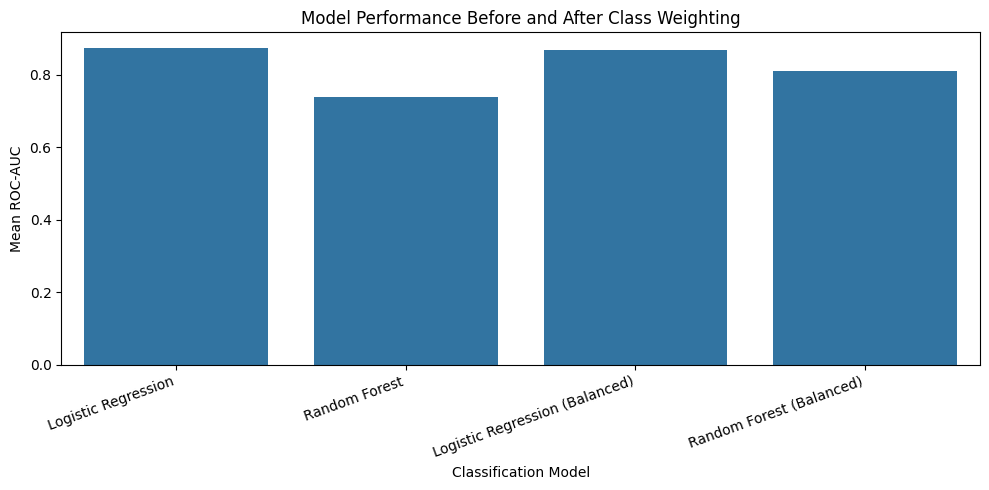

In [24]:

# Combine results from all four models
all_results = {
    **cv_results,
    **weighted_results
}

# Create a DataFrame of ROC-AUC scores
all_results_df = pd.DataFrame(all_results)

# Calculate summary statistics
comparison_df = pd.DataFrame({
    "Mean ROC-AUC": all_results_df.mean(),
    "Standard Deviation": all_results_df.std()
})

# Calculate improvement compared with original models
comparison_df["ROC-AUC Change"] = [
    0,
    0,
    comparison_df.loc[
        "Logistic Regression (Balanced)", "Mean ROC-AUC"
    ] - comparison_df.loc[
        "Logistic Regression", "Mean ROC-AUC"
    ],
    comparison_df.loc[
        "Random Forest (Balanced)", "Mean ROC-AUC"
    ] - comparison_df.loc[
        "Random Forest", "Mean ROC-AUC"
    ]
]

print("Comparison of all four models:")
display(comparison_df.round(4))

# Visualize mean ROC-AUC
plt.figure(figsize=(10, 5))

sns.barplot(
    x=comparison_df.index,
    y="Mean ROC-AUC",
    data=comparison_df.reset_index(names="Model")
)

plt.title("Model Performance Before and After Class Weighting")
plt.xlabel("Classification Model")
plt.ylabel("Mean ROC-AUC")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


#### Overall Comparison and Interpretation

The comparison of all four models shows that class weighting affects the two classification algorithms differently.

The original Logistic Regression model achieved the highest mean ROC-AUC of 0.8732, slightly outperforming its class-weighted version, which achieved 0.8691.

For Random Forest, class weighting improved the mean ROC-AUC from 0.7374 to 0.8097, representing an increase of approximately 0.0723.

Despite this improvement, the class-weighted Random Forest model did not outperform either Logistic Regression model.

Overall, Logistic Regression without class weighting achieved the best discrimination performance and the lowest variability across the five validation folds. Therefore, it is the strongest candidate among the four evaluated configurations.

These findings suggest that class weighting can improve the performance of certain algorithms when working with imbalanced datasets, but its effectiveness depends on the model.

In [25]:
# Calculate missing-value statistics for all CpG features
feature_missing = pd.DataFrame({
    "Missing Values": X.isnull().sum(),
    "Non-Missing Values": X.notnull().sum(),
    "Missing Percentage (%)": X.isnull().mean() * 100
})

# Sort features by missing percentage
feature_missing = feature_missing.sort_values(
    by="Missing Percentage (%)",
    ascending=False
)

display(feature_missing)

,Missing Values,Non-Missing Values,Missing Percentage (%)
CpG_14,990,10,99.0
CpG_25,990,10,99.0
CpG_33,990,10,99.0
CpG_46,36,964,3.6
CpG_13,35,965,3.5
CpG_27,33,967,3.3
CpG_42,32,968,3.2
CpG_5,31,969,3.1
CpG_48,31,969,3.1
CpG_0,30,970,3.0


#### Interpretation and Missing-Value Handling Decisions

The missing-value analysis revealed substantial differences in missingness across the CpG features.

Three features, CpG_14, CpG_25, and CpG_33, each contain 990 missing values, corresponding to 99% missingness. Since only 10 observations are available for each of these features, their measurements provide insufficient information for reliable median imputation.

Therefore, we exclude these three features from the analysis.

The remaining 47 CpG features contain between 1.5% and 3.6% missing values. We retain these features and use median imputation to handle their missing measurements.

Median imputation is less sensitive to extreme values than mean imputation. The imputation values are calculated using only the training data within each cross-validation fold to prevent data leakage.

This approach reduces the influence of highly incomplete features while preserving the majority of the available methylation information.

In [26]:
# Identify features with excessive missing values
features_to_drop = ["CpG_14", "CpG_25", "CpG_33"]

# Create the updated feature matrix
X = merged_df.drop(
    columns=[
        "Cell ID",
        "Chemotherapy_Resistance",
        *features_to_drop
    ]
)

# Keep the target variable unchanged
y = merged_df["Chemotherapy_Resistance"]

print("Excluded features:", features_to_drop)
print("Remaining features:", X.shape[1])
print("Number of observations:", X.shape[0])

Excluded features: ['CpG_14', 'CpG_25', 'CpG_33']
Remaining features: 47
Number of observations: 1000


#### Results After Feature Selection

After excluding CpG_14, CpG_25, and CpG_33 due to their 99% missingness, we repeated the five-fold cross-validation experiments using the remaining 47 features.

Logistic Regression achieved a mean ROC-AUC of 0.8732, with a standard deviation of 0.0235. Random Forest achieved a mean ROC-AUC of 0.7374, with a standard deviation of 0.0488.

The mean ROC-AUC values remained unchanged to four decimal places compared with the initial experiments using all 50 features.

This suggests that excluding the three highly incomplete features did not materially affect the observed predictive performance of either classifier. It also avoids relying on extensive imputation for features with very limited observed measurements.